In [23]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import is_string_dtype,is_float_dtype

In [24]:
df=pd.read_parquet("../data/bronze/holidays_events.parquet")
df

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
...,...,...,...,...,...,...
345,2017-12-22,Additional,National,Ecuador,Navidad-3,False
346,2017-12-23,Additional,National,Ecuador,Navidad-2,False
347,2017-12-24,Additional,National,Ecuador,Navidad-1,False
348,2017-12-25,Holiday,National,Ecuador,Navidad,False


In [25]:
df.shape

(350, 6)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   date         350 non-null    str  
 1   type         350 non-null    str  
 2   locale       350 non-null    str  
 3   locale_name  350 non-null    str  
 4   description  350 non-null    str  
 5   transferred  350 non-null    bool 
dtypes: bool(1), str(5)
memory usage: 32.1 KB


### MEMORIA

In [27]:
def memoria(df):
    df["date"]=pd.to_datetime(df["date"])
    for col in df.columns:
        if is_string_dtype(df[col]):
            df[col]=df[col].astype("category")
    return df

df=memoria(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         350 non-null    datetime64[us]
 1   type         350 non-null    category      
 2   locale       350 non-null    category      
 3   locale_name  350 non-null    category      
 4   description  350 non-null    category      
 5   transferred  350 non-null    bool          
dtypes: bool(1), category(4), datetime64[us](1)
memory usage: 8.2 KB


In [28]:
df.isnull().sum()

date           0
type           0
locale         0
locale_name    0
description    0
transferred    0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

### DISTRIBUCION

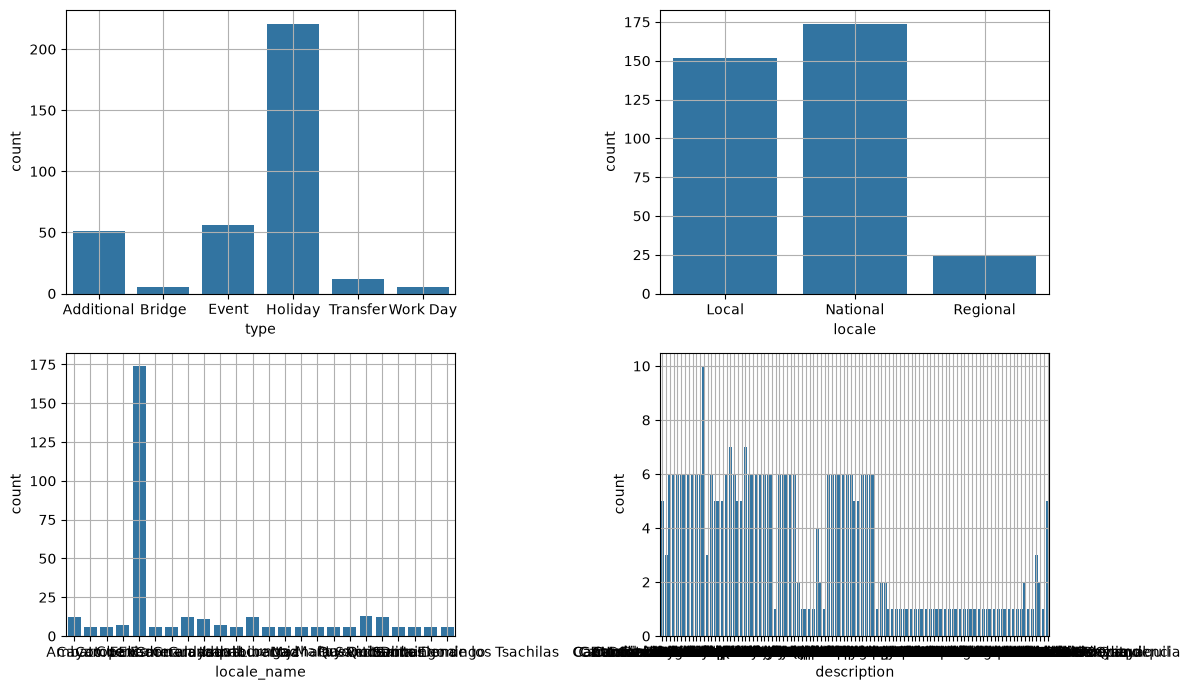

In [30]:
fig,ax=plt.subplots(2,2,figsize=(12,7))
for i,col in enumerate(df.select_dtypes(include="category").columns):
    sns.countplot(data=df,x=col,ax=ax.flat[i])
    ax.flat[i].grid()
plt.tight_layout()
plt.show()

## EDA PROFUNDO

In [31]:
pd.crosstab(df["type"],df["locale"])

locale,Local,National,Regional
type,,,
Additional,11,40,0
Bridge,0,5,0
Event,0,56,0
Holiday,137,60,24
Transfer,4,8,0
Work Day,0,5,0


In [32]:
pd.crosstab(df["locale_name"],df["type"])

type,Additional,Bridge,Event,Holiday,Transfer,Work Day
locale_name,,,,,,
Ambato,0,0,0,12,0,0
Cayambe,0,0,0,6,0,0
Cotopaxi,0,0,0,6,0,0
Cuenca,0,0,0,6,1,0
Ecuador,40,5,56,60,8,5
El Carmen,0,0,0,6,0,0
Esmeraldas,0,0,0,6,0,0
Guaranda,0,0,0,12,0,0
Guayaquil,5,0,0,5,1,0


In [33]:
cardinalidad = df.select_dtypes(include="category").nunique().sort_values(ascending=False)

print(cardinalidad)

description    103
locale_name     24
type             6
locale           3
dtype: int64


In [34]:
for col in df.select_dtypes(include="category").columns:

    print(f"\n--- {col} ---")

    frecuencia = df[col].value_counts()

    porcentaje = (
        df[col].value_counts(normalize=True) * 100
    ).round(2)

    resultado = pd.DataFrame({
        "frecuencia": frecuencia,
        "porcentaje": porcentaje
    })

    print(resultado.head(10))


--- type ---
            frecuencia  porcentaje
type                              
Holiday            221       63.14
Event               56       16.00
Additional          51       14.57
Transfer            12        3.43
Bridge               5        1.43
Work Day             5        1.43

--- locale ---
          frecuencia  porcentaje
locale                          
National         174       49.71
Local            152       43.43
Regional          24        6.86

--- locale_name ---
             frecuencia  porcentaje
locale_name                        
Ecuador             174       49.71
Quito                13        3.71
Ambato               12        3.43
Guaranda             12        3.43
Latacunga            12        3.43
Riobamba             12        3.43
Guayaquil            11        3.14
Cuenca                7        2.00
Ibarra                7        2.00
Cayambe               6        1.71

--- description ---
                            frecuencia  porcentaje


## GUARDAR

In [35]:
df.to_csv("../data/silver/holidays_events.csv",index=False,encoding="utf-8-sig")